# Modelado: pronóstico de incidentes y zonas de riesgo

El objetivo de esta etapa es pronosticar el número mensual de incidentes por parroquia, para identificar las zonas y los meses que requieren mayor atención turística. El archivo preparado tiene registros de incidentes y variables geográficas y temporales; por tanto, el problema se formula como una **regresión de conteos en una serie temporal por parroquia**, no como clasificación del subtipo. El análisis se limita a las etapas de división y selección inicial de algoritmos. No se crearán archivos auxiliares.

## 1. División del dataset (Data Splitting)

Como los registros están fechados y la aplicación busca anticipar incidentes, primero se agregan los eventos a una observación por parroquia y mes. Se construyen variables rezagadas que describen únicamente periodos anteriores. La división se realiza cronológicamente por mes: los periodos iniciales se destinan a entrenamiento, el bloque siguiente a validación y el bloque más reciente a prueba. Así se simula el uso futuro y se evita mezclar observaciones posteriores con las anteriores. No se aplica estratificación, ya que el objetivo es un conteo numérico y la serie debe conservar su orden temporal.

,partición,primer mes,último mes,meses,filas zona-mes
0,Entrenamiento,2022-07,2025-04,34,35315
1,Validación,2025-05,2025-12,8,8336
2,Prueba,2026-01,2026-08,8,8344


,métrica,valor
0,filas examinadas,17680253
1,filas inválidas descartadas,0
2,parroquias identificadas,1043
3,meses observados,62
4,filas parroquia-mes para modelar,64511


,provincia,Canton,Parroquia,incidentes_acumulados
Cod_Parroquia,,,,
90150,GUAYAS,GUAYAQUIL,"GUAYAQUIL, CABECERA CANTONAL Y CAPITAL PROVINCIAL",3015047
170150,PICHINCHA,QUITO,"QUITO DISTRITO METROPOLITANO, CABECERA CANTONA...",2940892
10150,AZUAY,CUENCA,"CUENCA, CABECERA CANTONAL Y CAPITAL PROVINCIAL.",699387
230150,SANTO DOMINGO DE LOS TSACHILAS,SANTO DOMINGO,"SANTO DOMINGO DE LOS COLORADOS, CABECERA CANTO...",503561
180150,TUNGURAHUA,AMBATO,"AMBATO, CABECERA CANTONAL Y CAPITAL PROVINCIAL",457988
70150,EL ORO,MACHALA,"MACHALA, CABECERA CANTONAL Y CAPITAL PROVINCIAL",374948
100150,IMBABURA,IBARRA,"SAN MIGUEL DE IBARRA, CABECERA CANTONAL Y CAPI...",373976
60150,CHIMBORAZO,RIOBAMBA,"RIOBAMBA, CABECERA CANTONAL Y CAPITAL PROVINCIAL",355014
110150,LOJA,LOJA,"LOJA, CABECERA CANTONAL Y CAPITAL PROVINCIAL",323143


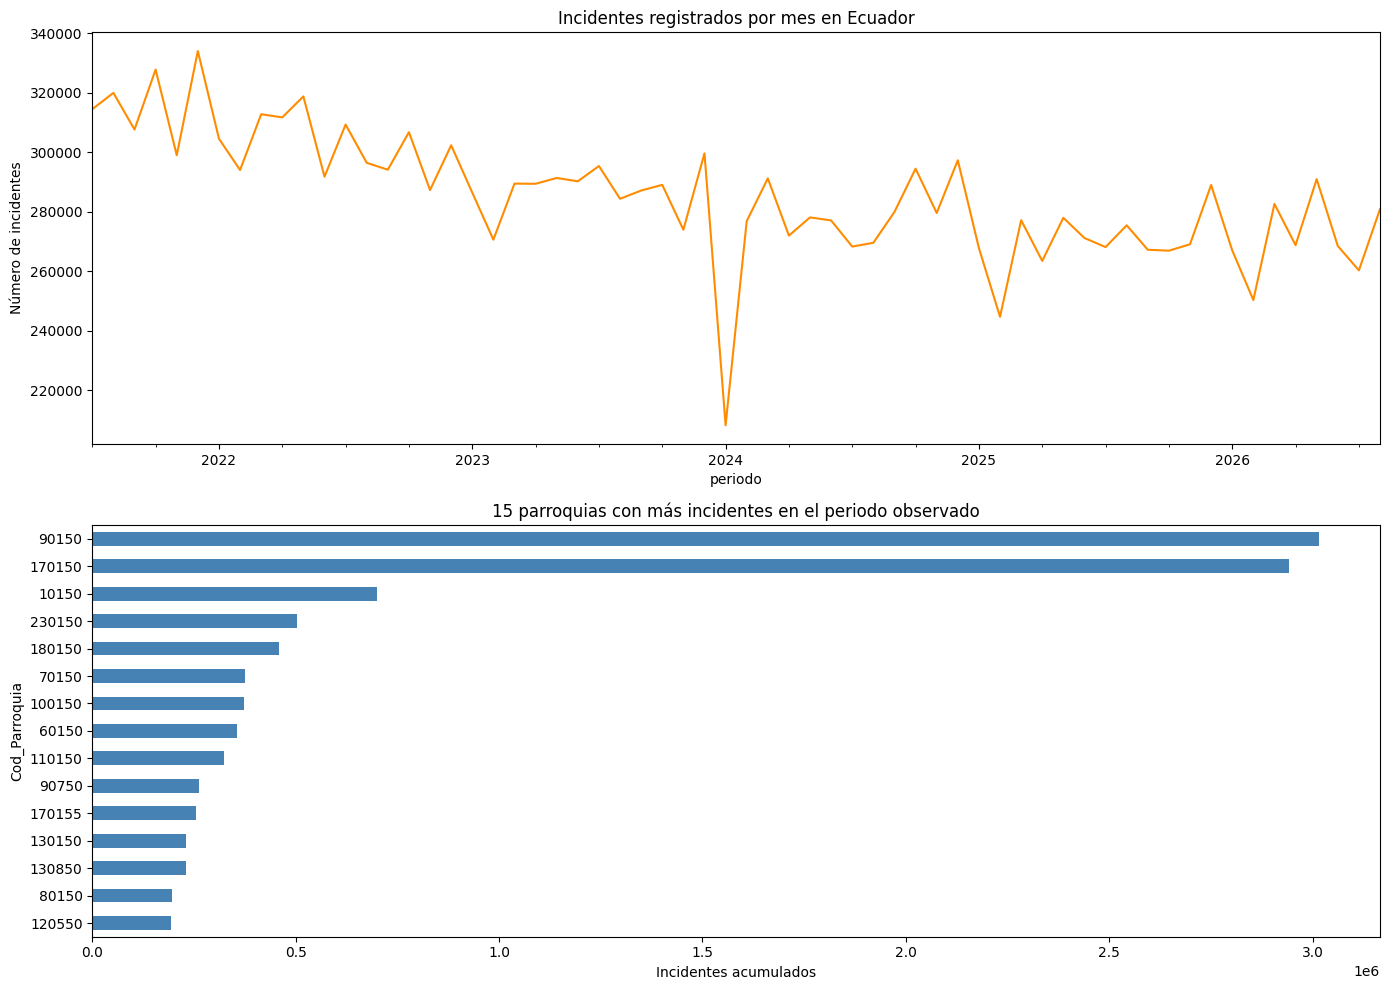

In [1]:
# Importar las herramientas estándar necesarias para la agregación temporal y visualización. 
from pathlib import Path  # Resolver la ruta del CSV de entrada.
import numpy as np  # Calcular variables cíclicas y métricas.
import pandas as pd  # Leer, agrupar y preparar los datos.
import matplotlib.pyplot as plt  # Graficar tendencias temporales y geográficas.
from IPython.display import display  # Mostrar tablas de resultados.

# Definir la fuente y limitar la memoria leyendo solo las columnas necesarias por bloques. 
RUTA_DATASET = next((ruta for ruta in (Path('data/processed/dataset_proyecto_preparado.csv'), Path('../data/processed/dataset_proyecto_preparado.csv')) if ruta.is_file()), Path('data/processed/dataset_proyecto_preparado.csv'))  # Usar el archivo preparado en la etapa anterior.
TAMANO_BLOQUE = 300_000  # Leer un número acotado de registros en cada iteración.
COLUMNAS_UBICACION = ['Cod_Parroquia', 'provincia', 'Canton', 'Parroquia']  # Identificar la unidad geográfica y sus etiquetas.
COLUMNAS_LECTURA = COLUMNAS_UBICACION + ['Anio', 'Mes']  # No leer variables de subtipo o servicio, que no definen el conteo total.
if not RUTA_DATASET.is_file():  # Comprobar la existencia de la fuente antes de procesarla.
    raise FileNotFoundError(f'No se encontró el dataset: {RUTA_DATASET}')  # Informar claramente si la ruta debe corregirse.

# Agrupar cada bloque y guardar metadatos geográficos para reducir los datos antes del modelado. 
bloques_mensuales = []  # Acumular conteos parciales por parroquia y mes.
bloques_ubicacion = []  # Acumular etiquetas descriptivas de las parroquias.
filas_leidas = 0  # Contabilizar el número de eventos revisados.
filas_invalidas = 0  # Contabilizar registros sin código o fecha mensual válida.
tipos_csv = {'Cod_Parroquia': 'string', 'provincia': 'string', 'Canton': 'string', 'Parroquia': 'string', 'Anio': 'float32', 'Mes': 'float32'}  # Preservar los códigos geográficos como texto.
for bloque in pd.read_csv(RUTA_DATASET, usecols=COLUMNAS_LECTURA, dtype=tipos_csv, chunksize=TAMANO_BLOQUE, encoding='utf-8', on_bad_lines='error'):  # Leer por bloques para no cargar el CSV completo.
    filas_leidas += len(bloque)  # Actualizar el total de filas procesadas.
    bloque['Cod_Parroquia'] = bloque['Cod_Parroquia'].str.strip().replace('', pd.NA)  # Limpiar el identificador geográfico.
    bloque['Anio'] = pd.to_numeric(bloque['Anio'], errors='coerce')  # Convertir el año y marcar formatos no válidos.
    bloque['Mes'] = pd.to_numeric(bloque['Mes'], errors='coerce')  # Convertir el mes y marcar formatos no válidos.
    valido = bloque['Cod_Parroquia'].notna() & bloque['Anio'].notna() & bloque['Mes'].between(1, 12) & (bloque['Anio'] % 1 == 0)  # Exigir ubicación, año entero y mes entre uno y doce.
    filas_invalidas += int((~valido).sum())  # Registrar filas que no pueden ubicarse en la serie mensual.
    bloque = bloque.loc[valido].copy()  # Excluir únicamente registros no utilizables para esta agregación.
    if bloque.empty:  # Evitar agrupar un bloque que no tenga eventos válidos.
        continue  # Pasar al siguiente bloque del CSV.
    bloque['Anio'] = bloque['Anio'].astype('int16')  # Reducir el tipo de año después de validar su integridad.
    bloque['Mes'] = bloque['Mes'].astype('int8')  # Reducir el tipo de mes después de validar su rango.
    bloque['periodo'] = pd.to_datetime({'year': bloque['Anio'], 'month': bloque['Mes'], 'day': 1}).dt.to_period('M')  # Representar el tiempo con resolución mensual.
    parcial = bloque.groupby(['Cod_Parroquia', 'periodo'], observed=True, sort=False).size().rename('incidentes').reset_index()  # Contar incidentes por parroquia y mes.
    bloques_mensuales.append(parcial)  # Guardar el agregado compacto del bloque.
    bloques_ubicacion.append(bloque[COLUMNAS_UBICACION].drop_duplicates('Cod_Parroquia'))  # Guardar nombres para presentar las zonas.

# Combinar los agregados y sumar conteos repetidos entre bloques. 
if not bloques_mensuales:  # Comprobar que el CSV contenía observaciones procesables.
    raise ValueError('No se encontraron filas con código parroquial, año y mes válidos.')  # Detener con un diagnóstico accionable.
incidentes_mensuales = pd.concat(bloques_mensuales, ignore_index=True).groupby(['Cod_Parroquia', 'periodo'], observed=True, sort=False)['incidentes'].sum().reset_index()  # Obtener el conteo mensual final por zona.
ubicaciones = pd.concat(bloques_ubicacion, ignore_index=True).drop_duplicates('Cod_Parroquia').set_index('Cod_Parroquia')  # Asociar un nombre descriptivo a cada código.
periodos_completos = pd.period_range(incidentes_mensuales['periodo'].min(), incidentes_mensuales['periodo'].max(), freq='M')  # Crear el calendario mensual observado.
codigos = ubicaciones.index  # Obtener las zonas presentes en el archivo.
celdas_panel = len(codigos) * len(periodos_completos)  # Estimar el tamaño del panel antes de materializarlo.
if celdas_panel > 5_000_000:  # Evitar una expansión accidental de memoria para una granularidad inesperada.
    raise MemoryError(f'El panel completo tendría {celdas_panel:,} filas; reduce la granularidad o usa una estrategia dispersa.')  # Hacer explícito el límite del enfoque.

# Completar meses sin eventos como cero desde el primer mes con registros de cada zona. 
indice_panel = pd.MultiIndex.from_product([codigos, periodos_completos], names=['Cod_Parroquia', 'periodo']).to_frame(index=False)  # Preparar combinaciones zona-mes.
primer_mes_zona = incidentes_mensuales.groupby('Cod_Parroquia', observed=True)['periodo'].min().rename('primer_mes')  # Identificar el inicio observable de cada zona.
panel = indice_panel.merge(primer_mes_zona, on='Cod_Parroquia', how='left')  # Añadir el inicio de registro a cada combinación.
panel = panel.loc[panel['periodo'] >= panel['primer_mes']].drop(columns='primer_mes')  # No inventar historia anterior a la primera observación de la zona.
panel = panel.merge(incidentes_mensuales, on=['Cod_Parroquia', 'periodo'], how='left')  # Añadir los conteos reales observados.
panel['incidentes'] = panel['incidentes'].fillna(0).astype('int32')  # Interpretar ausencia de fila durante el periodo observado como cero eventos.
panel = panel.merge(ubicaciones, left_on='Cod_Parroquia', right_index=True, how='left').sort_values(['Cod_Parroquia', 'periodo']).reset_index(drop=True)  # Incorporar nombres y ordenar cronológicamente.

# Construir predictores que solo consultan meses previos al mes que se pronostica. 
agrupado = panel.groupby('Cod_Parroquia', sort=False)['incidentes']  # Agrupar series por parroquia para calcular rezagos.
for rezago in [1, 2, 3, 6, 12]:  # Incluir memoria reciente y estacional anual.
    panel[f'lag_{rezago}'] = agrupado.shift(rezago)  # Usar exclusivamente el conteo del mes anterior correspondiente.
panel['media_movil_3'] = panel.groupby('Cod_Parroquia', sort=False)['incidentes'].transform(lambda serie: serie.shift(1).rolling(3, min_periods=3).mean())  # Calcular promedio de tres meses previos sin incluir el objetivo.
panel['media_movil_6'] = panel.groupby('Cod_Parroquia', sort=False)['incidentes'].transform(lambda serie: serie.shift(1).rolling(6, min_periods=6).mean())  # Calcular promedio semestral previo.
mes_objetivo = panel['periodo'].dt.month  # Obtener el mes calendario que se desea anticipar.
panel['mes_sin'] = np.sin(2 * np.pi * (mes_objetivo - 1) / 12)  # Codificar el ciclo anual preservando la proximidad diciembre-enero.
panel['mes_cos'] = np.cos(2 * np.pi * (mes_objetivo - 1) / 12)  # Completar la representación cíclica del mes.
panel['tendencia_meses'] = panel['periodo'].astype('int64') - int(periodos_completos[0].ordinal)  # Representar el avance temporal sin consultar valores futuros.
COLUMNAS_REZAGO = ['lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'media_movil_3', 'media_movil_6']  # Enumerar predictores que exigen historia completa.
datos_modelables = panel.dropna(subset=COLUMNAS_REZAGO).copy()  # Excluir los primeros meses sin historial suficiente.
if datos_modelables['periodo'].nunique() < 24:  # Comprobar que existan suficientes meses supervisados para una evaluación temporal.
    raise ValueError('Hay menos de 24 meses con rezagos disponibles; se requiere más historia para entrenar, validar y probar una serie temporal.')  # Evitar presentar una estimación temporal inestable.

# Dividir por periodos cronológicos, nunca por filas aleatorias. 
periodos_modelables = np.array(sorted(datos_modelables['periodo'].unique()))  # Ordenar los meses que tienen predictores completos.
cantidad_test = max(1, round(len(periodos_modelables) * 0.15))  # Reservar aproximadamente el 15 por ciento de los meses más recientes.
cantidad_validacion = max(1, round(len(periodos_modelables) * 0.15))  # Reservar aproximadamente el 15 por ciento anterior a prueba.
cantidad_train = len(periodos_modelables) - cantidad_validacion - cantidad_test  # Asignar los meses iniciales al entrenamiento.
if cantidad_train < 12:  # Verificar que el bloque de entrenamiento tenga longitud razonable.
    raise ValueError('El bloque de entrenamiento tiene menos de doce meses; añade historial temporal antes de continuar.')  # Explicar por qué la división no es suficiente.
periodos_train = periodos_modelables[:cantidad_train]  # Definir el bloque más antiguo para aprender.
periodos_validacion = periodos_modelables[cantidad_train:cantidad_train + cantidad_validacion]  # Definir el bloque intermedio para comparar algoritmos.
periodos_test = periodos_modelables[cantidad_train + cantidad_validacion:]  # Mantener los meses más recientes reservados para evaluación final.
entrenamiento = datos_modelables[datos_modelables['periodo'].isin(periodos_train)].copy()  # Extraer filas del bloque de entrenamiento.
validacion = datos_modelables[datos_modelables['periodo'].isin(periodos_validacion)].copy()  # Extraer filas del bloque de validación.
prueba = datos_modelables[datos_modelables['periodo'].isin(periodos_test)].copy()  # Extraer filas del bloque de prueba.
resumen_particiones = pd.DataFrame({'partición': ['Entrenamiento', 'Validación', 'Prueba'], 'primer mes': [periodos_train[0], periodos_validacion[0], periodos_test[0]], 'último mes': [periodos_train[-1], periodos_validacion[-1], periodos_test[-1]], 'meses': [len(periodos_train), len(periodos_validacion), len(periodos_test)], 'filas zona-mes': [len(entrenamiento), len(validacion), len(prueba)]})  # Documentar los límites y tamaños temporales.
display(resumen_particiones)  # Mostrar la separación cronológica aplicada.

# Presentar el volumen temporal agregado y las principales parroquias por volumen histórico. 
serie_nacional = incidentes_mensuales.groupby('periodo', observed=True)['incidentes'].sum().sort_index()  # Sumar eventos de todas las zonas por mes.
conteo_zona = incidentes_mensuales.groupby('Cod_Parroquia', observed=True)['incidentes'].sum().sort_values(ascending=False)  # Ordenar zonas por volumen total observado.
tabla_zonas = ubicaciones.join(conteo_zona.rename('incidentes_acumulados')).sort_values('incidentes_acumulados', ascending=False).head(15)  # Obtener las quince zonas con más registros.
display(pd.DataFrame({'métrica': ['filas examinadas', 'filas inválidas descartadas', 'parroquias identificadas', 'meses observados', 'filas parroquia-mes para modelar'], 'valor': [filas_leidas, filas_invalidas, len(codigos), len(periodos_completos), len(panel)]}))  # Resumir el alcance y la limpieza temporal.
display(tabla_zonas)  # Mostrar las zonas con mayor volumen histórico.
fig, ejes = plt.subplots(2, 1, figsize=(14, 10))  # Preparar visualizaciones de tiempo y ubicación.
serie_nacional.plot(ax=ejes[0], color='darkorange')  # Graficar evolución mensual de incidentes en el conjunto del país.
ejes[0].set_title('Incidentes registrados por mes en Ecuador')  # Titular la serie nacional.
ejes[0].set_ylabel('Número de incidentes')  # Etiquetar el eje del volumen.
tabla_zonas['incidentes_acumulados'].sort_values().plot(kind='barh', ax=ejes[1], color='steelblue')  # Graficar parroquias con mayor volumen.
ejes[1].set_title('15 parroquias con más incidentes en el periodo observado')  # Titular el ranking histórico.
ejes[1].set_xlabel('Incidentes acumulados')  # Aclarar que el ranking muestra conteos y no tasas de riesgo.
plt.tight_layout()  # Ajustar espacios entre gráficos.
plt.show()  # Mostrar las dos visualizaciones.

### Hallazgos y análisis

Las tablas calculan las filas examinadas, las observaciones descartadas por código o fecha inválidos, las parroquias encontradas, el rango temporal y los tamaños de cada partición. Los gráficos muestran la evolución mensual nacional y las parroquias con mayores conteos acumulados. La partición respeta el orden del tiempo y la validación precede a la prueba; las primeras observaciones de cada parroquia se omiten hasta disponer de rezagos suficientes. Los meses sin eventos se representan como cero desde el primer mes observado de cada parroquia, supuesto que debe contrastarse con la cobertura del registro. `Cod_Parroquia` permite localizar una zona administrativa, pero el archivo no incluye coordenadas para ubicar puntos exactos.

**Conclusión.** La unidad de pronóstico queda definida como el conteo mensual por parroquia y los bloques train/validation/test preservan el orden temporal. Esta estrategia es más adecuada que el muestreo aleatorio o la estratificación para anticipar meses futuros y reduce la fuga de información. Los resultados representan volúmenes de incidentes registrados, no tasas de peligro ajustadas por población o presencia de turistas; tampoco identifican coordenadas puntuales.

## 2. Selección y definición de algoritmos

El problema es una **regresión de conteos mensuales no negativos por parroquia**. Se compara una línea base estacional —el mismo conteo de doce meses antes— con dos candidatos: `PoissonRegressor` y `RandomForestRegressor`. Poisson es apropiado para conteos y entrega una media esperada no negativa; además, el One-Hot disperso permite incorporar la parroquia sin asignar un orden artificial a sus códigos. Random Forest puede aprender interacciones y patrones no lineales entre rezagos, calendario y ubicación, aunque demanda más cómputo y no extrapola bien tendencias. Los modelos se ajustan solo con entrenamiento y se comparan sobre validación; la prueba se mantiene intacta para la etapa posterior de evaluación final. Se usa MAE como criterio primario, interpretable como error medio en incidentes por parroquia-mes.

,modelo,MAE_incidentes,RMSE_incidentes,devianza_Poisson
2,RandomForestRegressor,18.866779,124.770141,3.391618
0,Baseline estacional (lag 12),29.979846,241.324173,10.047897
1,PoissonRegressor,395.724878,2182.171988,1422.126984


Menor MAE de validación: RandomForestRegressor. La selección es preliminar y la prueba permanece reservada.


,periodo,incidentes_reales,incidentes_predichos
0,2025-05,277710,264100.675875
1,2025-06,270875,270863.949469
2,2025-07,267854,268883.165643
3,2025-08,275139,266706.704335
4,2025-09,266957,270047.582429
5,2025-10,266612,269880.637962
6,2025-11,268782,266932.254067
7,2025-12,288715,266447.487509


,periodo,Cod_Parroquia,provincia,Canton,Parroquia,incidentes,incidentes_predichos
61155,2025-12,90150,GUAYAS,GUAYAQUIL,"GUAYAQUIL, CABECERA CANTONAL Y CAPITAL PROVINCIAL",52244,49176.478381
26280,2025-12,170150,PICHINCHA,QUITO,"QUITO DISTRITO METROPOLITANO, CABECERA CANTONA...",48103,44586.399127
2717,2025-12,10150,AZUAY,CUENCA,"CUENCA, CABECERA CANTONAL Y CAPITAL PROVINCIAL.",12299,10756.332847
41852,2025-12,230150,SANTO DOMINGO DE LOS TSACHILAS,SANTO DOMINGO,"SANTO DOMINGO DE LOS COLORADOS, CABECERA CANTO...",8140,7361.848055
30062,2025-12,180150,TUNGURAHUA,AMBATO,"AMBATO, CABECERA CANTONAL Y CAPITAL PROVINCIAL",7420,6778.664436
115,2025-12,100150,IMBABURA,IBARRA,"SAN MIGUEL DE IBARRA, CABECERA CANTONAL Y CAPI...",6631,5519.229425
53189,2025-12,70150,EL ORO,MACHALA,"MACHALA, CABECERA CANTONAL Y CAPITAL PROVINCIAL",5329,5247.365282
49779,2025-12,60150,CHIMBORAZO,RIOBAMBA,"RIOBAMBA, CABECERA CANTONAL Y CAPITAL PROVINCIAL",5657,5029.018409
6499,2025-12,110150,LOJA,LOJA,"LOJA, CABECERA CANTONAL Y CAPITAL PROVINCIAL",5230,4993.953281
26590,2025-12,170155,PICHINCHA,QUITO,CALDERÓN (CARAPUNGO),4305,3657.925123


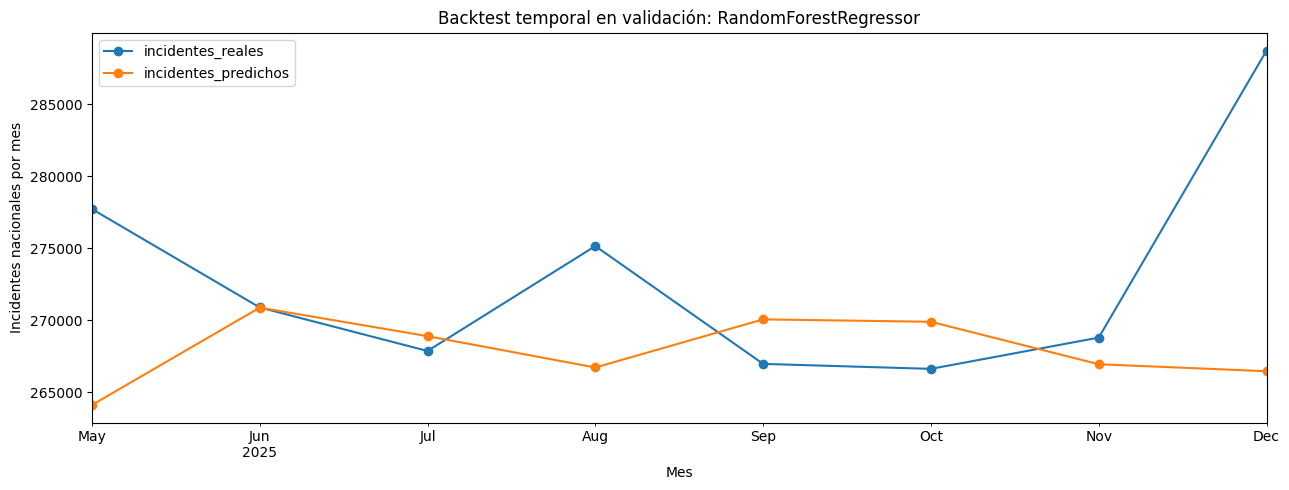

In [2]:
# Importar modelos estándar de regresión de conteos y métricas de validación. 
from sklearn.compose import ColumnTransformer  # Aplicar codificación a la ubicación y pasar características numéricas.
from sklearn.impute import SimpleImputer  # Resolver faltantes categóricos dentro del ajuste.
from sklearn.pipeline import Pipeline  # Mantener juntas las transformaciones y el estimador.
from sklearn.preprocessing import OneHotEncoder  # Codificar parroquias sin tratarlas como números ordenados.
from sklearn.linear_model import PoissonRegressor  # Modelar la media de un conteo no negativo.
from sklearn.ensemble import RandomForestRegressor  # Probar interacciones no lineales como candidato de ensemble.
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_poisson_deviance  # Comparar error absoluto, cuadrático y devianza.

# Definir las entradas temporales y geográficas disponibles antes del mes objetivo. 
COLUMNAS_CATEGORICAS = ['Cod_Parroquia', 'provincia', 'Canton']  # Usar código y contexto administrativo como categorías.
COLUMNAS_NUMERICAS = ['lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'media_movil_3', 'media_movil_6', 'mes_sin', 'mes_cos', 'tendencia_meses']  # Incluir historial, estacionalidad y tendencia.
PREDICTORES = COLUMNAS_CATEGORICAS + COLUMNAS_NUMERICAS  # Excluir el conteo objetivo y los atributos de incidente.
OBJETIVO = 'incidentes'  # Predecir la cantidad de incidentes en cada parroquia-mes.
X_train = entrenamiento[PREDICTORES]  # Separar entradas de entrenamiento.
y_train = entrenamiento[OBJETIVO].astype('float64')  # Asegurar el tipo numérico requerido por regresión.
X_validacion = validacion[PREDICTORES]  # Separar entradas de validación sin reajustar transformaciones.
y_validacion = validacion[OBJETIVO].astype('float64')  # Conservar los conteos observados para comparar predicciones.

# Codificar las variables geográficas y dejar intactas las variables numéricas. 
transformador_categorico = Pipeline([('imputar', SimpleImputer(strategy='constant', fill_value='SIN_DATO')), ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=20, sparse_output=True))])  # Agrupar categorías escasas y tolerar zonas nuevas.
preprocesador = ColumnTransformer([('geografia', transformador_categorico, COLUMNAS_CATEGORICAS), ('temporal', 'passthrough', COLUMNAS_NUMERICAS)], remainder='drop')  # Evitar fuga al ajustar el vocabulario con train solamente.

# Definir el baseline estacional y dos modelos candidatos con motivos complementarios. 
prediccion_baseline = validacion['lag_12'].to_numpy(dtype='float64')  # Usar como referencia el valor observado doce meses antes.
modelos = {'PoissonRegressor': Pipeline([('preprocesar', preprocesador), ('modelo', PoissonRegressor(alpha=0.1, max_iter=300, tol=1e-5))]), 'RandomForestRegressor': Pipeline([('preprocesar', preprocesador), ('modelo', RandomForestRegressor(n_estimators=80, max_depth=18, min_samples_leaf=10, max_features=0.8, n_jobs=-1, random_state=42))])}  # Limitar profundidad y tamaño de hojas para controlar costo y sobreajuste.
predicciones_validacion = {'Baseline estacional (lag 12)': prediccion_baseline}  # Iniciar la comparación con el baseline.
for nombre, modelo in modelos.items():  # Ajustar cada candidato por separado, usando solo entrenamiento.
    modelo.fit(X_train, y_train)  # Aprender transformaciones y modelo con el bloque temporal más antiguo.
    predicciones_validacion[nombre] = np.maximum(modelo.predict(X_validacion), 0)  # Predecir el bloque siguiente y evitar conteos negativos.

# Calcular métricas para comparar modelos sin consultar el conjunto de prueba. 
filas_metricas = []  # Reservar las métricas de cada alternativa.
for nombre, predicciones in predicciones_validacion.items():  # Evaluar baseline y candidatos en las mismas observaciones.
    predicciones_seguras = np.maximum(np.asarray(predicciones, dtype='float64'), 1e-9)  # Mantener predicciones válidas para la devianza de Poisson.
    filas_metricas.append({'modelo': nombre, 'MAE_incidentes': mean_absolute_error(y_validacion, predicciones), 'RMSE_incidentes': np.sqrt(mean_squared_error(y_validacion, predicciones)), 'devianza_Poisson': mean_poisson_deviance(y_validacion, predicciones_seguras)})  # Medir errores en conteos de parroquia-mes.
metricas_validacion = pd.DataFrame(filas_metricas).sort_values('MAE_incidentes')  # Ordenar por el criterio principal de negocio.
display(metricas_validacion)  # Mostrar el rendimiento comparativo en validación.
mejor_nombre = metricas_validacion.iloc[0]['modelo']  # Identificar el menor MAE observado en validación.
if mejor_nombre == 'Baseline estacional (lag 12)':  # Verificar si algún candidato mejora la referencia simple.
    print('Ningún candidato supera al baseline estacional según MAE en validación.')  # Evitar afirmar que un modelo complejo es mejor sin evidencia.
else:  # Informar qué algoritmo candidato lideró la comparación.
    print(f'Menor MAE de validación: {mejor_nombre}. La selección es preliminar y la prueba permanece reservada.')  # Explicitar el alcance de la selección.

# Analizar el total nacional predicho por mes de validación con el candidato de menor MAE. 
if mejor_nombre == 'Baseline estacional (lag 12)':  # Usar el baseline si ningún candidato lo superó.
    prediccion_elegida = prediccion_baseline  # Conservar la referencia estacional como mejor alternativa preliminar.
else:  # Recuperar predicciones del candidato elegido en validación.
    prediccion_elegida = predicciones_validacion[mejor_nombre]  # No reajustar ni consultar la prueba.
resultado_validacion = validacion[['periodo', 'Cod_Parroquia', 'provincia', 'Canton', 'Parroquia', 'incidentes']].copy()  # Preparar resultados interpretables por periodo y zona.
resultado_validacion['incidentes_predichos'] = prediccion_elegida  # Incorporar las estimaciones del modelo elegido.
resumen_mensual_validacion = resultado_validacion.groupby('periodo', observed=True).agg(incidentes_reales=('incidentes', 'sum'), incidentes_predichos=('incidentes_predichos', 'sum')).reset_index()  # Agregar predicciones a nivel nacional por mes.
display(resumen_mensual_validacion)  # Mostrar meses observados y anticipados durante el backtest.
ultimo_mes_validacion = resultado_validacion['periodo'].max()  # Seleccionar el último periodo del bloque de validación.
zonas_riesgo_validacion = resultado_validacion.loc[resultado_validacion['periodo'] == ultimo_mes_validacion].sort_values('incidentes_predichos', ascending=False).head(15)  # Ordenar zonas por incidentes esperados en ese mes.
display(zonas_riesgo_validacion[['periodo', 'Cod_Parroquia', 'provincia', 'Canton', 'Parroquia', 'incidentes', 'incidentes_predichos']])  # Mostrar el ranking geográfico previsto y lo realmente observado.
resumen_mensual_validacion.set_index('periodo')[['incidentes_reales', 'incidentes_predichos']].plot(figsize=(13, 5), marker='o')  # Comparar evolución mensual real y estimada.
plt.title(f'Backtest temporal en validación: {mejor_nombre}')  # Identificar el modelo utilizado en la gráfica.
plt.ylabel('Incidentes nacionales por mes')  # Etiquetar el total mensual.
plt.xlabel('Mes')  # Etiquetar el eje temporal.
plt.tight_layout()  # Ajustar el área del gráfico.
plt.show()  # Presentar el backtest mensual.

### Hallazgos y análisis

La tabla de validación compara el baseline estacional y ambos candidatos mediante MAE, RMSE y devianza de Poisson; menor es mejor en las tres métricas. MAE expresa el error medio en número de incidentes por parroquia-mes, mientras que RMSE penaliza más los errores grandes. La tabla mensual contrasta el total real y el estimado; el ranking final muestra las parroquias con más incidentes esperados en el último mes de validación, junto con su conteo real. Estos resultados de backtesting son evidencia para seleccionar un algoritmo, no todavía una alerta futura ni una evaluación final: la partición de prueba no se ha utilizado.

**Conclusión.** Poisson y Random Forest se justifican por la naturaleza de conteo y la posibilidad de capturar patrones no lineales, respectivamente; la comparación con `lag_12` evita aceptar complejidad sin mejora demostrable. El menor MAE en validación determina un candidato preliminar, pero debe superar la prueba cronológica en la siguiente fase antes de considerarse para alertas. El ranking disponible se refiere a parroquias y volumen esperado: no equivale a riesgo por turista ni a coordenadas de puntos peligrosos. Para construir alertas geográficas precisas se necesitarían georreferenciación, datos de exposición o afluencia turística y criterios de umbral acordados con el dominio.